In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
empleados = pd.read_csv('C:\\Users\\super\\OneDrive\\Escritorio\\phyton\\empleados.csv')

In [21]:
print(empleados.head())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

In [22]:
empleados[['DistanceFromHome','TotalWorkingYears','YearsAtCompany','StandardHours','Age']].agg(['mean','median','std','var'])

,DistanceFromHome,TotalWorkingYears,YearsAtCompany,StandardHours,Age
mean,9.192517,11.279592,7.008163,80.0,36.923810
median,7.000000,10.000000,5.000000,80.0,36.000000
std,8.106864,7.780782,6.126525,0.0,9.135373
var,65.721251,60.540563,37.534310,0.0,83.455049


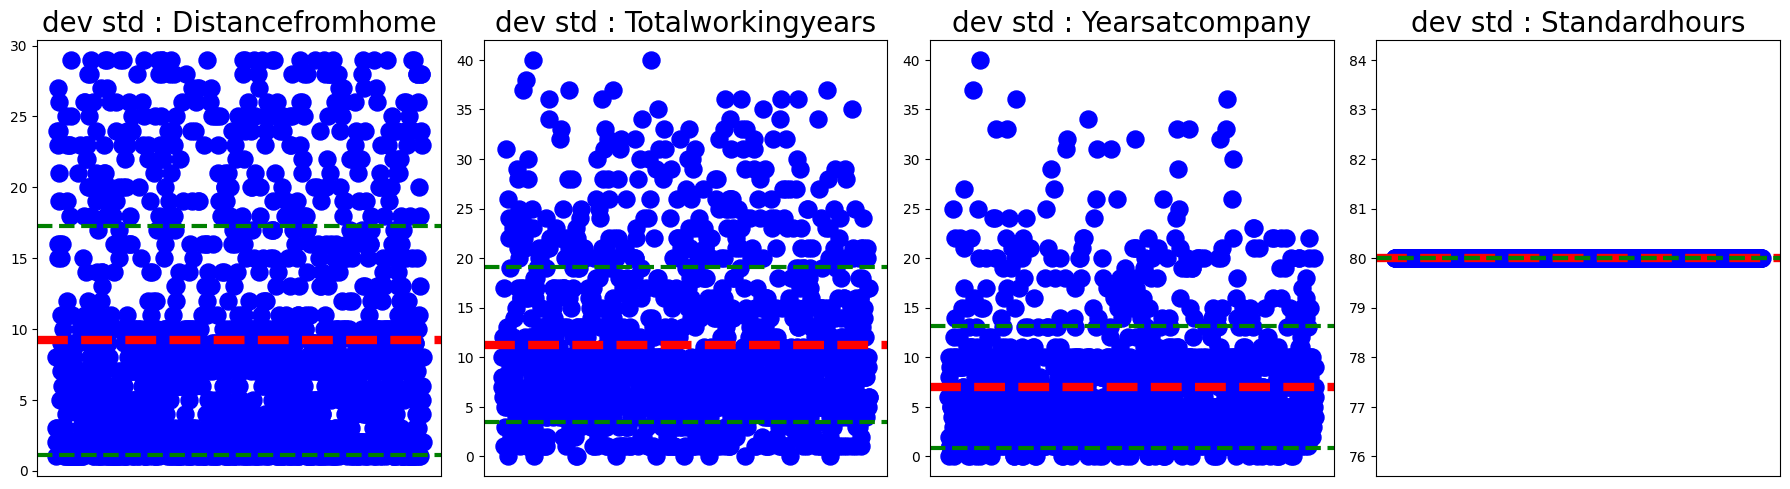

In [ ]:
def subgrafica_std(empleados,columna,fig,posicion):
     ax=fig.add_subplot(1,4,posicion)
     media = empleados[columna].mean()
     std = empleados[columna].std()
     ax.scatter(range(len(empleados[columna])), empleados[columna],
                marker='o', color='blue', s=150)
     ax.axhline(media, color='red', linestyle='--', linewidth=6)
     ax.axhline(media + std, color='green', linestyle='--', linewidth=3)
     ax.axhline(media - std, color='green', linestyle='--', linewidth=3)
     ax.set_title("dev std : "+ columna.capitalize(),fontsize=20)
     ax.set_xticks(range(len(empleados[columna])))
     ax.get_xaxis().set_visible(False)
fig=plt.figure(figsize=(18, 5))
subgrafica_std(empleados,'DistanceFromHome',fig,1)
subgrafica_std(empleados,'TotalWorkingYears',fig,2)
subgrafica_std(empleados,'YearsAtCompany',fig,3)
subgrafica_std(empleados,'StandardHours',fig,4)
plt.tight_layout()
plt.show()
#generamos un grafico de dispersion para ver la dispercion de los datos y la desviacion estandar de cada variable, podemos notar que la mayoria de los datos se concentran alrededor de la media y poor debajo de ella ,el volumen de datos se ve mas disperso en la distancia desde la casa al trabajo y en los años de experiencia, mientras que en las horas estandar(practicamente la misma para todos) y el tiempo en la compañia se concentran mas alrededor de la media.

In [6]:
empleados_seleccionados= empleados[['DistanceFromHome','TotalWorkingYears','YearsAtCompany','StandardHours','Age']]

In [ ]:
empleados_seleccionados.cov()
# podemos notar una relacion positiva entre los años de experiencia y la edad de los empleados, el tiempo en la compañia y la edad, en la mayoria de variables poca relacion que nos agan intuir que la distancia de la casa del empleado tienen relacion con los años de experiencia, tiempo en la compañia y edad del empleado.

,DistanceFromHome,TotalWorkingYears,YearsAtCompany,StandardHours,Age
DistanceFromHome,65.721251,0.291951,0.472219,0.0,-0.124873
TotalWorkingYears,0.291951,60.540563,29.942577,0.0,48.361684
YearsAtCompany,0.472219,29.942577,37.534310,0.0,17.423359
StandardHours,0.000000,0.000000,0.000000,0.0,0.000000
Age,-0.124873,48.361684,17.423359,0.0,83.455049


                   DistanceFromHome  TotalWorkingYears
DistanceFromHome           1.000000           0.004628
TotalWorkingYears          0.004628           1.000000 

                  DistanceFromHome  YearsAtCompany
DistanceFromHome          1.000000        0.009508
YearsAtCompany            0.009508        1.000000 

                  DistanceFromHome       Age
DistanceFromHome          1.000000 -0.001686
Age                      -0.001686  1.000000 



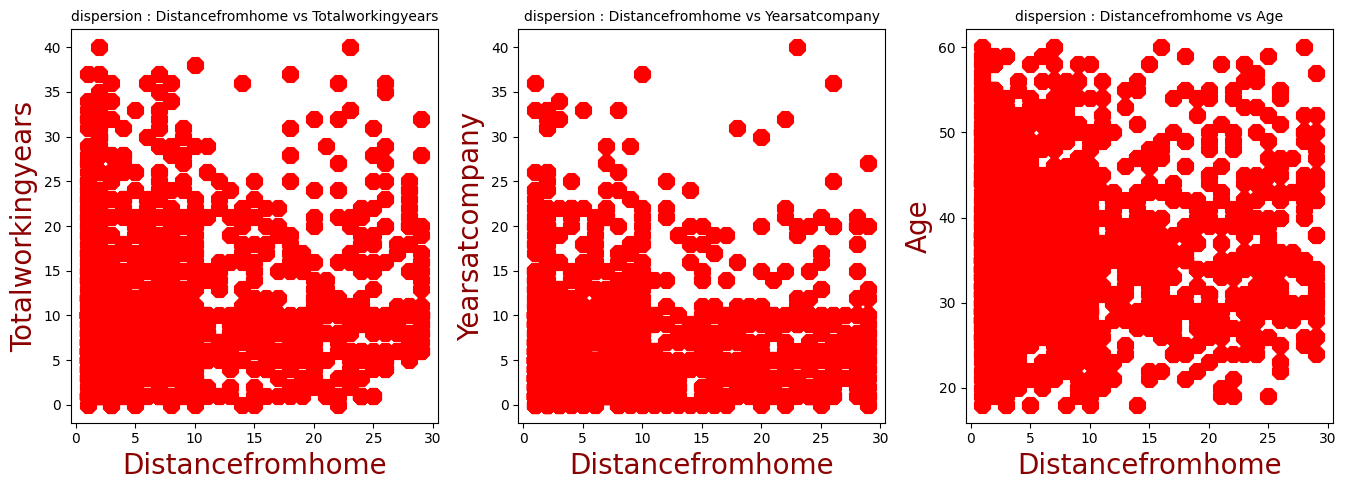



                   TotalWorkingYears       Age
TotalWorkingYears           1.000000  0.680381
Age                         0.680381  1.000000 

                YearsAtCompany       Age
YearsAtCompany        1.000000  0.311309
Age                   0.311309  1.000000 

                   TotalWorkingYears  YearsAtCompany
TotalWorkingYears           1.000000        0.628133
YearsAtCompany              0.628133        1.000000 



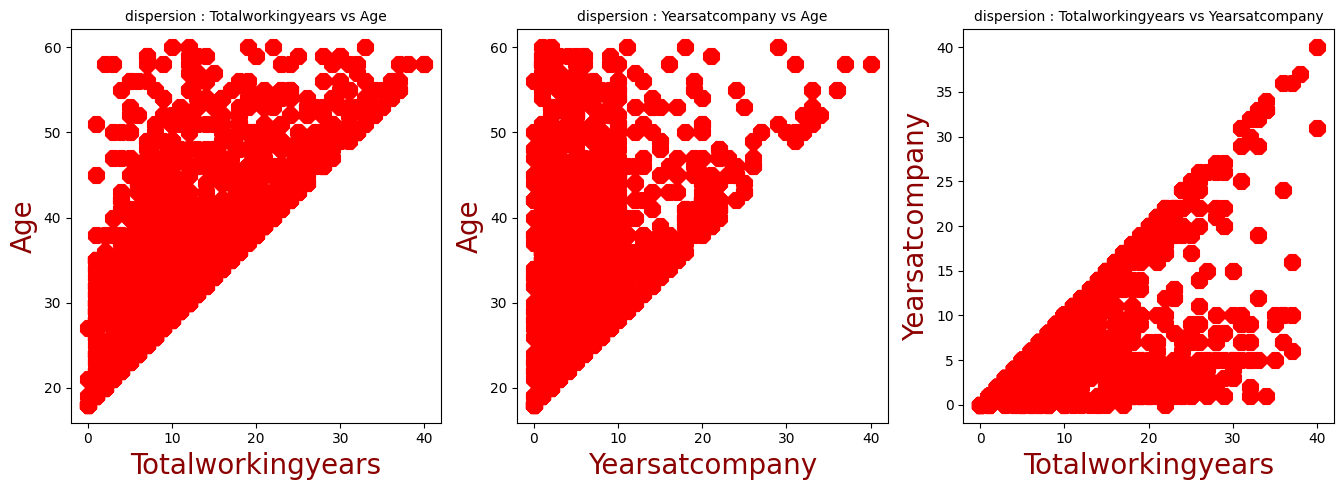

In [ ]:
def subgrafica_dispersion(empleados_seleccionados,columna1,columna2,fig,posicion):
     ax=fig.add_subplot(1,4,posicion)
     ax.scatter(empleados_seleccionados[columna1], empleados_seleccionados[columna2],
                marker='8', color='red', s=150)
     ax.set_title("dispersion : "+ columna1.capitalize() + " vs " + columna2.capitalize(),fontsize=10)
     ax.set_xlabel(columna1.capitalize(), fontsize=20 ,color='darkred')
     ax.set_ylabel(columna2.capitalize(), fontsize=20 ,color='darkred')
print(empleados_seleccionados[['DistanceFromHome','TotalWorkingYears']].corr(), '\n')
print(empleados_seleccionados[['DistanceFromHome','YearsAtCompany']].corr(), '\n')
print(empleados_seleccionados[['DistanceFromHome','Age']].corr(), '\n')

fig=plt.figure(figsize=(18, 5))
subgrafica_dispersion(empleados_seleccionados,'DistanceFromHome','TotalWorkingYears',fig,1)
subgrafica_dispersion(empleados_seleccionados,'DistanceFromHome','YearsAtCompany',fig,2)
subgrafica_dispersion(empleados_seleccionados,'DistanceFromHome','Age',fig,3)
plt.tight_layout()
plt.show()
#podemos notar que la distancia desde la casa al trabajo no tiene una relacion significativa con los años de experiencia, tiempo en la compañia y edad del empleado, ya que el coeficiente de correlacion es cercano a 0, lo que indica que no hay una relacion lineal entre estas variables.
print('\n')
print(empleados_seleccionados[['TotalWorkingYears','Age']].corr(), '\n')
print(empleados_seleccionados[['YearsAtCompany','Age']].corr(), '\n')
print(empleados_seleccionados[['TotalWorkingYears','YearsAtCompany']].corr(), '\n')
fig=plt.figure(figsize=(18, 5))
subgrafica_dispersion(empleados_seleccionados,'TotalWorkingYears','Age',fig,1)
subgrafica_dispersion(empleados_seleccionados,'YearsAtCompany','Age',fig,2)
subgrafica_dispersion(empleados_seleccionados,'TotalWorkingYears','YearsAtCompany',fig,3)
plt.tight_layout()
plt.show()
#podemos notar que los años de experiencia y el tiempo en la compañia tienen una relacion positiva con la edad del empleado, ya que el coeficiente de correlacion es cercano a 1, lo que indica que hay una relacion lineal entre estas variables.